# Classification ⇄ Regression (2 ทาง, sklearn + XGBoost/LightGBM + Stacking)

**Flow — เลือกทิศทางได้ที่ CONFIG:**
- `DIRECTION = 'cls2reg'` → **[Stage 1]** ทำนาย class (`CLASS_COL`) → เอาผล (probability + class ทำนาย) มาเป็น feature → **[Stage 2]** ทำนายค่าต่อเนื่อง (`REG_COL`)
- `DIRECTION = 'reg2cls'` → **[Stage 1]** ทำนายค่าต่อเนื่อง (`REG_COL`) → เอาค่าที่ทำนายมาเป็น feature → **[Stage 2]** ทำนาย class (`CLASS_COL`)

| Stage | วัดผล |
|---|---|
| Classification | Accuracy, F1 (macro/weighted), confusion matrix |
| Regression | R², RMSE, MAE |

**การกัน data leakage:**
- Stage 2 ใช้ **out-of-fold prediction** จาก train (ไม่ใช่ผลจากโมเดลที่เห็น train ตัวเอง)
- ทุก preprocessing (impute / winsorize / scale / one-hot) อยู่ใน Pipeline ที่ fit เฉพาะ train
- ablation: "ไม่มี / ทำนาย / ของจริง" เพื่อวัดว่า Stage 1 ช่วย Stage 2 แค่ไหน
- **Self-check อัตโนมัติ** (section 8) ตรวจ leak + overfit ท้าย notebook

**ลำดับ:** 0 โหลด → 1 config+ตรวจ → 2 prep+split → 3 Stage 1 → 4 สร้าง feature → 5 Stage 2 → 6 end-to-end → 7 ทางเลือก → 8 self-check

## 0. โหลดข้อมูล

In [1]:
import pandas as pd

DATA_PATH = 'data.csv'   # ← แก้เป็น path ของคุณ (หรือใช้ df = your_dataframe.copy())

df = pd.read_csv(DATA_PATH)
df.head()

,app_id,age,income,emp_years,term_months,region,prior_defaults,default,loan_amount
0,1,56.2,32790.0,4.9,36,N,0,yes,22067.7
1,2,37.0,24720.0,11.0,36,W,0,no,14420.4
2,3,44.2,37650.0,1.8,36,E,1,yes,18728.4
3,4,54.8,40710.0,6.9,12,S,0,no,20459.8
4,5,39.3,NaN,0.0,24,W,1,no,23351.9


## 1. Config + ตรวจข้อมูลคร่าว ๆ

In [2]:
import warnings
# กรองเฉพาะ warning ที่รก ๆ (ไม่ปิดทั้งหมด เพื่อไม่พลาด warning สำคัญ)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')

# ============ CONFIG (แก้ตรงนี้) ============
CLASS_COL = 'default'         # คอลัมน์ class (สำหรับ classify)
REG_COL   = 'loan_amount'     # คอลัมน์ y ต่อเนื่อง (สำหรับ regress)
DROP_COLS = ['app_id']        # คอลัมน์ที่ไม่ใช้ (ID / ชื่อ / วันที่)

DIRECTION  = 'cls2reg'        # 'cls2reg': class -> reg | 'reg2cls': reg -> class

TEST_SIZE = 0.2
SEED      = 42
N_SPLITS  = 5

MAX_NULL_COL  = 0.50   # null เกินนี้ -> ตัดคอลัมน์
ADD_INDICATOR = 0.05   # null เกินนี้ -> เพิ่ม flag _missing
MAX_CARD      = 20     # คอลัมน์ข้อความที่มีค่าต่างกันเกินนี้ -> ตัด (น่าจะเป็น ID)

CLS_METRIC   = 'f1_macro'   # 'accuracy' | 'f1_macro' | 'f1_weighted'
CLASS_WEIGHT = None         # None | 'balanced'

USE_LOG_TARGET   = False    # True = regress บน log1p(y)
ADD_PROBA        = True     # cls2reg: เพิ่ม probability เป็น feature ของ Stage 2
ADD_CLASS_ONEHOT = True     # cls2reg: เพิ่ม class ทำนาย (one-hot) เป็น feature
ADD_PRED_VALUE   = True     # reg2cls: เพิ่มค่า y ที่ทำนายเป็น feature (scale ด้วย stat ของ train)
ADD_PRED_BIN     = True     # reg2cls: เพิ่ม bin ของค่าที่ทำนาย (one-hot)

WINSORIZE = True            # ตัดหางเสี้ยว outlier ของ numeric ที่ quantile (fit จาก train เท่านั้น)
WINSOR_LO = 0.01
WINSOR_HI = 0.99
# ==========================================

TASK1 = 'classification' if DIRECTION == 'cls2reg' else 'regression'
TASK2 = 'regression'      if DIRECTION == 'cls2reg' else 'classification'
print('Stage 1 =', TASK1, '| Stage 2 =', TASK2)

Stage 1 = classification | Stage 2 = regression


shape: (800, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   app_id          800 non-null    int64  
 1   age             800 non-null    float64
 2   income          785 non-null    float64
 3   emp_years       800 non-null    float64
 4   term_months     800 non-null    int64  
 5   region          800 non-null    object 
 6   prior_defaults  800 non-null    int64  
 7   default         800 non-null    object 
 8   loan_amount     800 non-null    float64
dtypes: float64(4), int64(3), object(2)
memory usage: 56.4+ KB


,n_null,pct_null
income,15,1.88


,count,pct
default,,
no,591,73.9
yes,209,26.1


class ที่เป็น null (จะโดนตัด): 0
Baseline accuracy (ทาย class บ่อยสุด) = 0.739  <- โมเดลต้องเอาชนะอันนี้


,count,mean,std,min,median,max
default,,,,,,
no,591,18758.610,4659.764,3265.0,18830.8,33469.1
yes,209,16527.787,4644.133,5919.5,16565.8,26888.7


eta^2 (สัดส่วนการกระจายของ y ที่อธิบายได้ด้วย class) = 0.043
   ใกล้ 0 = class ไม่ค่อยเกี่ยวกับ y | สูง (>0.3) = สอง stage น่าจะช่วยกันได้
skew ของ y = -0.1 (เกิน ±1 -> ลอง USE_LOG_TARGET = True)


C:\Users\computer\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3649 (\N{THAI CHARACTER SARA AE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\computer\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3618 (\N{THAI CHARACTER YO YAK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\computer\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3585 (\N{THAI CHARACTER KO KAI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\computer\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3605 (\N{THAI CHARACTER TO TAO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\computer\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: Us

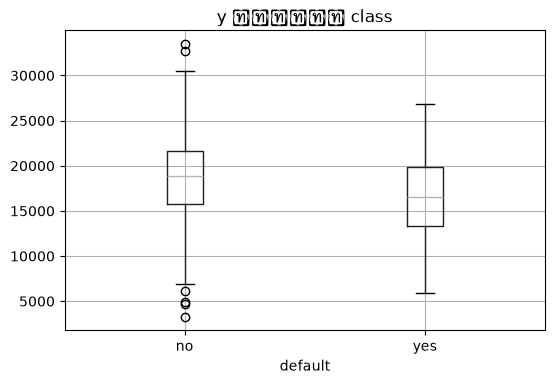

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

assert CLASS_COL in df.columns, f'ไม่พบคอลัมน์ {CLASS_COL}'
assert REG_COL in df.columns, f'ไม่พบคอลัมน์ {REG_COL}'

print('shape:', df.shape)
df.info()

# --- null ---
nr = pd.DataFrame({'n_null': df.isna().sum(), 'pct_null': (df.isna().mean() * 100).round(2)})
display(nr[nr.n_null > 0].sort_values('pct_null', ascending=False))

# --- class ---
vc = df[CLASS_COL].value_counts()
display(pd.DataFrame({'count': vc, 'pct': (vc / vc.sum() * 100).round(1)}))
print('class ที่เป็น null (จะโดนตัด):', int(df[CLASS_COL].isna().sum()))
print(f'Baseline accuracy (ทาย class บ่อยสุด) = {vc.max() / vc.sum():.3f}  <- โมเดลต้องเอาชนะอันนี้')
if vc.min() / vc.max() < 0.3:
    print('!! class ไม่สมดุล -> เน้น F1 และ/หรือตั้ง CLASS_WEIGHT = "balanced"')

# --- y ตาม class ---
display(df.groupby(CLASS_COL)[REG_COL].agg(['count', 'mean', 'std', 'min', 'median', 'max']).round(3))
tmp = df[[CLASS_COL, REG_COL]].dropna()
g = tmp[REG_COL].mean()
eta2 = tmp.groupby(CLASS_COL)[REG_COL].apply(lambda s: len(s) * (s.mean() - g) ** 2).sum() / ((tmp[REG_COL] - g) ** 2).sum()
print(f'eta^2 (สัดส่วนการกระจายของ y ที่อธิบายได้ด้วย class) = {eta2:.3f}')
print('   ใกล้ 0 = class ไม่ค่อยเกี่ยวกับ y | สูง (>0.3) = สอง stage น่าจะช่วยกันได้')
print('skew ของ y =', round(tmp[REG_COL].skew(), 2), '(เกิน ±1 -> ลอง USE_LOG_TARGET = True)')

tmp.boxplot(column=REG_COL, by=CLASS_COL, figsize=(6, 4)); plt.suptitle(''); plt.title('y แยกตาม class'); plt.show()

## 2. Data prep + split (กัน leak + รองรับข้อมูลสกปรกครบ)

สิ่งที่รองรับอัตโนมัติ:
- **แถว**: ตัดแถวซ้ำ / ตัดแถวที่ target เป็น missing
- **missing หลายแบบ**: `NaN`, `None`, `inf`, และข้อความ marker (`'na'`, `'n/a'`, `'null'`, `'-'`, `'?'`, ช่องว่าง)
- **ตัวเลขที่เก็บเป็นข้อความ**: `"51,598"`, `"45%"`, `"$1,200"` → แปลงกลับเป็นตัวเลข
- **คอลัมน์**: ตัด null เยอะ / datetime / ค่าคงที่ / ข้อความ high-cardinality (ID-like) / ชื่อคอลัมน์ซ้ำ
- **outlier**: winsorize ที่ quantile 1%/99% — fit จาก **train เท่านั้น** และข้ามคอลัมน์ flag 0/1
- **ข้อมูลใหม่ตอน predict**: unknown category ไม่พัง (`handle_unknown='ignore'`)
- ทุก preprocessing อยู่ใน Pipeline fit เฉพาะ train + split แบบ **stratified** ตาม class

In [4]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin

# ---------- เครื่องมือกันข้อมูลสกปรก ----------
MISSING_MARKERS = {'', 'na', 'n/a', 'nan', 'null', 'none', '-', '?', 'n.a.', '#n/a', 'nil'}

def to_num(s):
    """แปลง series เป็นตัวเลข — ตัด comma / % / สกุลเงินออกก่อน แปลงไม่ได้เป็น NaN"""
    if pd.api.types.is_numeric_dtype(s):
        return s.astype(float)
    t = s.astype('string').str.strip()
    for ch in [',', '%', '$', '฿', '€']:
        t = t.str.replace(ch, '', regex=False)
    return pd.to_numeric(t, errors='coerce')

class Winsorizer(BaseEstimator, TransformerMixin):
    """ตัดหางเสี้ยวที่ quantile ของ train
    คอลัมน์ที่ quantile ต่ำ = quantile สูง (เช่น flag 0/1 ที่เอียง) จะถูกข้าม ไม่ถูก clip"""
    def __init__(self, lo=0.01, hi=0.99):
        self.lo, self.hi = lo, hi
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_ = np.nanquantile(X, self.lo, axis=0)
        self.hi_ = np.nanquantile(X, self.hi, axis=0)
        self.skip_ = (self.hi_ - self.lo_) < 1e-12
        return self
    def transform(self, X):
        X = np.asarray(X, dtype=float).copy()
        lo = np.where(self.skip_, -np.inf, self.lo_)
        hi = np.where(self.skip_, np.inf, self.hi_)
        return np.clip(X, lo, hi)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

# ---------- ทำความสะอาด ----------
data = df.drop_duplicates().copy()

# ชื่อคอลัมน์ซ้ำ -> ตรวจก่อน (ถ้ามีจะพังทันที)
dup_cols = sorted({c for c in data.columns if list(data.columns).count(c) > 1})
if dup_cols:
    raise ValueError(f'ชื่อคอลัมน์ซ้ำ: {dup_cols}')

# marker ข้อความที่แท้จริงคือ missing -> NaN
n_marker = 0
for c in data.columns:
    if data[c].dtype == object:
        s = data[c].astype('string').str.strip()
        mask = s.str.lower().isin(MISSING_MARKERS)
        n_marker += int(mask.sum())
        data[c] = s.mask(mask)
if n_marker:
    print(f'ทำ marker (na/null/-/? ฯลฯ) เป็น missing: {n_marker} ค่า')

# REG_COL ต้องเป็นตัวเลข ("51,598" / "45%" ก็แปลงได้) — แปลงไม่ได้ = missing = ตัดแถว
data[REG_COL] = to_num(data[REG_COL])
n_bad_target = int(data[REG_COL].isna().sum()) + int(data[CLASS_COL].isna().sum())
data = data.dropna(subset=[CLASS_COL, REG_COL])
print(f'ตัดแถว target เป็น missing ไป: {n_bad_target} แถว')

# inf -> NaN (กัน scaler พัง)
n_inf = int(np.isinf(data.select_dtypes('number').to_numpy(dtype=float)).sum()) if len(data.select_dtypes('number').columns) else 0
data = data.replace([np.inf, -np.inf], np.nan)
if n_inf:
    print(f'แปลง inf -> missing: {n_inf} ค่า')

data = data.drop(columns=[c for c in DROP_COLS if c in data.columns])
feat = [c for c in data.columns if c not in (CLASS_COL, REG_COL)]

# คอลัมน์ข้อความที่แท้จริงเป็นตัวเลข ("51,598") -> แปลงกลับ (กันโดน one-hot แล้วตัดทิ้ง)
converted = []
for c in feat:
    if pd.api.types.is_numeric_dtype(data[c]):
        continue
    conv = to_num(data[c])
    non_null = int(data[c].notna().sum())
    if non_null > 0 and int(conv.notna().sum()) >= 0.9 * non_null:
        data[c] = conv.astype(float)
        converted.append(c)
if converted:
    print('แปลงข้อความ -> ตัวเลข:', converted)

# ตัดคอลัมน์ null เยอะ
ratio = data[feat].isna().mean()
too_null = ratio[ratio > MAX_NULL_COL].index.tolist()
feat = [c for c in feat if c not in too_null]

# ตัดคอลัมน์ datetime
dt_cols = [c for c in feat if pd.api.types.is_datetime64_any_dtype(data[c])]
feat = [c for c in feat if c not in dt_cols]

# ตัดคอลัมน์ค่าคงที่
const_cols = [c for c in feat if data[c].nunique(dropna=False) <= 1]
feat = [c for c in feat if c not in const_cols]

# ตัดคอลัมน์ข้อความ high-cardinality (ID-like)
obj_like = [c for c in feat if not pd.api.types.is_numeric_dtype(data[c])]
too_card = [c for c in obj_like if data[c].nunique(dropna=True) > MAX_CARD]
feat = [c for c in feat if c not in too_card]
print('ตัด (null เยอะ):', too_null, '| ตัด (datetime):', dt_cols,
      '| ตัด (ค่าคงที่):', const_cols, '| ตัด (cardinality สูง):', too_card)

ind_cols = [c for c in feat if data[c].isna().mean() > ADD_INDICATOR]
raw_feat = feat.copy()
cat_cols = [c for c in feat if not pd.api.types.is_numeric_dtype(data[c])]
num_cols = [c for c in feat if c not in cat_cols] + [c + '_missing' for c in ind_cols]
print('numeric:', len(num_cols), '| categorical:', cat_cols, '| flag _missing:', ind_cols)

def clean_X(d_):
    """ทำ X ให้พร้อมเข้า pipeline (เหมือนกันทุกครั้ง รวมตอน predict ข้อมูลใหม่)"""
    X_ = d_[raw_feat].copy()
    for c in ind_cols:
        X_[c + '_missing'] = X_[c].isna().astype(int)
    for c in cat_cols:
        X_[c] = X_[c].astype(object).fillna('missing').astype(str)
    return X_

def make_prep():
    """Pipeline ของ preprocessing — fit บน train เท่านั้น (กัน leak)"""
    num_steps = [('imp', SimpleImputer(strategy='median'))]
    if WINSORIZE:
        num_steps.append(('win', Winsorizer(WINSOR_LO, WINSOR_HI)))
    num_steps.append(('sc', StandardScaler()))
    steps = [('num', Pipeline(num_steps), num_cols)]
    if cat_cols:   # กันกรณีไม่มีคอลัมน์ categorical
        steps.append(('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols))
    return ColumnTransformer(steps)

X_all = clean_X(data)
le = LabelEncoder()
yc_all = le.fit_transform(data[CLASS_COL])
class_names = [str(c) for c in le.classes_]
yr_all = data[REG_COL].to_numpy(float)
K = len(class_names)
print('classes:', dict(enumerate(class_names)))

# ถ้าจะใช้ log1p(y) แต่ y มีค่า <= -1 -> ปิดให้เอง
if USE_LOG_TARGET and np.nanmin(yr_all) <= -1:
    print('!! y มีค่า <= -1 ทำให้ log1p ใช้ไม่ได้ -> ปิด USE_LOG_TARGET')
    USE_LOG_TARGET = False

try:
    idx_tr, idx_te = train_test_split(np.arange(len(X_all)), test_size=TEST_SIZE, random_state=SEED, stratify=yc_all)
except ValueError:
    print('!! stratify ไม่ได้ (บาง class มีตัวอย่างน้อยเกิน) -> split ธรรมดา')
    idx_tr, idx_te = train_test_split(np.arange(len(X_all)), test_size=TEST_SIZE, random_state=SEED)

X_train, X_test = X_all.iloc[idx_tr], X_all.iloc[idx_te]
yc_train, yc_test = yc_all[idx_tr], yc_all[idx_te]
yr_train, yr_test = yr_all[idx_tr], yr_all[idx_te]
print('train:', X_train.shape, ' test:', X_test.shape)
print('รองรับ: duplicates / inf / NaN / markers / ตัวเลขเป็นข้อความ / ID-datetime-ค่าคงที่ / outlier / unknown category')

ตัดแถว target เป็น missing ไป: 0 แถว
ตัด (null เยอะ): [] | ตัด (datetime): [] | ตัด (ค่าคงที่): [] | ตัด (cardinality สูง): []
numeric: 5 | categorical: ['region'] | flag _missing: []
classes: {0: 'no', 1: 'yes'}
train: (640, 6)  test: (160, 6)
รองรับ: duplicates / inf / NaN / markers / ตัวเลขเป็นข้อความ / ID-datetime-ค่าคงที่ / outlier / unknown category


## 3. Stage 1

### 3.1 เปรียบเทียบโมเดล (เลือกด้วย CV บน train — test ไม่ถูกใช้ตอนเลือก)

รวมทุกตระกูลหลัก: Logistic/KNN/SVC/NaiveBayes/DecisionTree/RandomForest/**ExtraTrees**/GradBoost/**HistGB**/**XGBoost**/**LightGBM**(ถ้าติดตั้ง)/**MLP**/**Stacking** + baseline

In [5]:
import numpy as np, pandas as pd, time
from sklearn.model_selection import StratifiedKFold, KFold, cross_validate, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              GradientBoostingClassifier, GradientBoostingRegressor,
                              ExtraTreesClassifier, ExtraTreesRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor,
                              StackingClassifier, StackingRegressor)
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import TransformedTargetRegressor
from sklearn.base import clone
from xgboost import XGBClassifier, XGBRegressor

# LightGBM — ถ้าติดตั้งไว้จะถูกใช้อัตโนมัติ (pip install lightgbm)
try:
    from lightgbm import LGBMClassifier, LGBMRegressor
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False
print('LightGBM:', 'ใช้ได้' if HAS_LGBM else 'ไม่ได้ติดตั้ง -> pip install lightgbm เพื่อเปิดใช้')

# ---------- CV scheme ของ classification (กัน class น้อยเกิน) ----------
min_cls = int(np.bincount(yc_train).min())
if min_cls >= 2:
    K_CV = max(2, min(N_SPLITS, min_cls))
    cv_cls = StratifiedKFold(K_CV, shuffle=True, random_state=SEED)
else:
    K_CV = max(2, min(N_SPLITS, len(yc_train)))
    cv_cls = KFold(K_CV, shuffle=True, random_state=SEED)
    print('!! มี class ที่มีตัวอย่าง < 2 -> ใช้ KFold ธรรมดาแทน StratifiedKFold')
cv_reg = KFold(N_SPLITS, shuffle=True, random_state=SEED)

# ---------- โมเดล ----------
def wrap_log(m):
    return TransformedTargetRegressor(regressor=m, func=np.log1p, inverse_func=np.expm1) if USE_LOG_TARGET else m

def make_svr():
    # SVR ต้อง scale y (+ log ถ้าเปิด USE_LOG_TARGET)
    tr = ([('log', FunctionTransformer(np.log1p, inverse_func=np.expm1))] if USE_LOG_TARGET else []) + [('sc', StandardScaler())]
    return TransformedTargetRegressor(regressor=SVR(C=10), transformer=Pipeline(tr))

CLS_MODELS = {
    'Logistic':     lambda: LogisticRegression(max_iter=2000, class_weight=CLASS_WEIGHT),
    'KNN':          lambda: KNeighborsClassifier(n_neighbors=7),
    'SVC':          lambda: SVC(probability=True, class_weight=CLASS_WEIGHT, random_state=SEED),
    'NaiveBayes':   lambda: GaussianNB(),
    'DecisionTree': lambda: DecisionTreeClassifier(max_depth=6, class_weight=CLASS_WEIGHT, random_state=SEED),
    'RandomForest': lambda: RandomForestClassifier(n_estimators=200, class_weight=CLASS_WEIGHT, random_state=SEED, n_jobs=-1),
    'ExtraTrees':   lambda: ExtraTreesClassifier(n_estimators=300, class_weight=CLASS_WEIGHT, random_state=SEED, n_jobs=-1),
    'GradBoost':    lambda: GradientBoostingClassifier(random_state=SEED),
    'HistGB':       lambda: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1,
                                                           class_weight=CLASS_WEIGHT, random_state=SEED),
    'XGBoost':      lambda: XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=4,
                                          subsample=0.9, colsample_bytree=0.9, tree_method='hist',
                                          random_state=SEED, n_jobs=-1, verbosity=0),
    'MLP':          lambda: MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=800,
                                          early_stopping=True, random_state=SEED),
}
REG_MODELS = {
    'Linear':       lambda: wrap_log(LinearRegression()),
    'Ridge':        lambda: wrap_log(Ridge(alpha=1.0)),
    'Lasso':        lambda: wrap_log(Lasso(alpha=0.1, max_iter=20000)),
    'ElasticNet':   lambda: wrap_log(ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=20000)),
    'KNN':          lambda: wrap_log(KNeighborsRegressor(n_neighbors=7)),
    'SVR':          make_svr,
    'DecisionTree': lambda: wrap_log(DecisionTreeRegressor(max_depth=6, random_state=SEED)),
    'RandomForest': lambda: wrap_log(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)),
    'ExtraTrees':   lambda: wrap_log(ExtraTreesRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)),
    'GradBoost':    lambda: wrap_log(GradientBoostingRegressor(random_state=SEED)),
    'HistGB':       lambda: wrap_log(HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=SEED)),
    'XGBoost':      lambda: wrap_log(XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                  subsample=0.9, colsample_bytree=0.9, tree_method='hist',
                                                  random_state=SEED, n_jobs=-1, verbosity=0)),
    'MLP':          lambda: wrap_log(MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=800,
                                                  early_stopping=True, random_state=SEED)),
}
if HAS_LGBM:
    CLS_MODELS['LightGBM'] = lambda: LGBMClassifier(n_estimators=300, learning_rate=0.1, num_leaves=31,
                                                    subsample=0.9, colsample_bytree=0.9,
                                                    class_weight=CLASS_WEIGHT, random_state=SEED,
                                                    n_jobs=-1, verbose=-1)
    REG_MODELS['LightGBM'] = lambda: wrap_log(LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31,
                                                            subsample=0.9, colsample_bytree=0.9,
                                                            random_state=SEED, n_jobs=-1, verbose=-1))

# Stacking: ensemble ของโมเดลแกร่ง 4 ตัว + meta-learner
def make_stack_cls():
    return StackingClassifier(
        estimators=[('xgb', CLS_MODELS['XGBoost']()), ('gb', CLS_MODELS['GradBoost']()),
                    ('hgb', CLS_MODELS['HistGB']()), ('rf', CLS_MODELS['RandomForest']())],
        final_estimator=LogisticRegression(max_iter=2000, class_weight=CLASS_WEIGHT),
        cv=3, n_jobs=-1)
def make_stack_reg():
    return StackingRegressor(
        estimators=[('xgb', REG_MODELS['XGBoost']()), ('gb', REG_MODELS['GradBoost']()),
                    ('hgb', REG_MODELS['HistGB']())],
        final_estimator=Ridge(alpha=1.0), cv=3, n_jobs=-1)
CLS_MODELS['Stacking'] = make_stack_cls
REG_MODELS['Stacking'] = make_stack_reg

print('โมเดล classification:', sorted(CLS_MODELS))
print('โมเดล regression   :', sorted(REG_MODELS))

def make_stage1_pipe(est):
    return Pipeline([('prep', make_prep()), ('est', est)])

def rank_stage1():
    rows = []
    if TASK1 == 'classification':
        cand = {'Baseline(majority)': lambda: DummyClassifier(strategy='most_frequent'), **CLS_MODELS}
        y1_tr, y1_te = yc_train, yc_test
        scoring = {'accuracy': 'accuracy', 'f1_macro': 'f1_macro', 'f1_weighted': 'f1_weighted'}
        cv = cv_cls
    else:
        cand = {'Baseline(mean)': lambda: DummyRegressor(), **REG_MODELS}
        y1_tr, y1_te = yr_train, yr_test
        scoring = {'r2': 'r2', 'neg_rmse': 'neg_root_mean_squared_error', 'neg_mae': 'neg_mean_absolute_error'}
        cv = cv_reg
    for name, mk in cand.items():
        t0 = time.time()
        pipe = make_stage1_pipe(mk())
        cvr = cross_validate(pipe, X_train, y1_tr, cv=cv, scoring=scoring, n_jobs=-1)
        pipe.fit(X_train, y1_tr)
        p = pipe.predict(X_test)
        row = {'model': name, 'fit_s': time.time() - t0}
        if TASK1 == 'classification':
            row.update({'CV_accuracy': cvr['test_accuracy'].mean(), 'CV_f1_macro': cvr['test_f1_macro'].mean(),
                        'CV_f1_weighted': cvr['test_f1_weighted'].mean(),
                        'Test_acc': accuracy_score(y1_te, p),
                        'Test_f1_macro': f1_score(y1_te, p, average='macro'),
                        'Test_f1_weighted': f1_score(y1_te, p, average='weighted')})
            key = 'CV_' + CLS_METRIC
        else:
            row.update({'CV_R2': cvr['test_r2'].mean(), 'CV_RMSE': -cvr['test_neg_rmse'].mean(),
                        'CV_MAE': -cvr['test_neg_mae'].mean(),
                        'Test_R2': r2_score(y1_te, p),
                        'Test_RMSE': np.sqrt(mean_squared_error(y1_te, p)),
                        'Test_MAE': mean_absolute_error(y1_te, p)})
            key = 'CV_R2'
        rows.append(row)
        print(f'{name:<18} {key}={row[key]:.4f}  [{row["fit_s"]:.1f}s]')
    out = pd.DataFrame(rows).sort_values(key, ascending=False).reset_index(drop=True)
    out.insert(0, 'rank', out.index + 1)
    return out

s1_df = rank_stage1()
display(s1_df.round(4))

LightGBM: ใช้ได้
โมเดล classification: ['DecisionTree', 'ExtraTrees', 'GradBoost', 'HistGB', 'KNN', 'LightGBM', 'Logistic', 'MLP', 'NaiveBayes', 'RandomForest', 'SVC', 'Stacking', 'XGBoost']
โมเดล regression   : ['DecisionTree', 'ElasticNet', 'ExtraTrees', 'GradBoost', 'HistGB', 'KNN', 'Lasso', 'LightGBM', 'Linear', 'MLP', 'RandomForest', 'Ridge', 'SVR', 'Stacking', 'XGBoost']


Baseline(majority) CV_f1_macro=0.4250  [2.8s]


Logistic           CV_f1_macro=0.7166  [2.3s]


KNN                CV_f1_macro=0.6363  [2.1s]


SVC                CV_f1_macro=0.6880  [2.1s]
NaiveBayes         CV_f1_macro=0.7173  [0.0s]
DecisionTree       CV_f1_macro=0.6618  [0.0s]


...

HistGB             CV_f1_macro=0.6839  [2.1s]


XGBoost            CV_f1_macro=0.6999  [0.5s]
MLP                CV_f1_macro=0.6313  [0.2s]


LightGBM           CV_f1_macro=0.6768  [0.9s]


Stacking           CV_f1_macro=0.6730  [4.1s]


,rank,model,fit_s,CV_accuracy,CV_f1_macro,CV_f1_weighted,Test_acc,Test_f1_macro,Test_f1_weighted
0,1,NaiveBayes,0.0428,0.7969,0.7173,0.7890,0.7500,0.6484,0.7382
1,2,Logistic,2.2724,0.8078,0.7166,0.7935,0.7562,0.6397,0.7370
2,3,GradBoost,0.2642,0.8000,0.7133,0.7887,0.7188,0.5752,0.6925
3,4,XGBoost,0.5100,0.7891,0.6999,0.7780,0.7062,0.5907,0.6940
4,5,RandomForest,0.6830,0.7875,0.6901,0.7731,0.7312,0.5645,0.6925
5,6,SVC,2.1288,0.8016,0.6880,0.7780,0.7312,0.5849,0.7020
6,7,ExtraTrees,0.7281,0.7844,0.6856,0.7699,0.7125,0.5508,0.6788
7,8,HistGB,2.0845,0.7750,0.6839,0.7649,0.7125,0.5794,0.6918
8,9,LightGBM,0.8934,0.7719,0.6768,0.7606,0.7312,0.6184,0.7170
9,10,Stacking,4.1214,0.7922,0.6730,0.7674,0.7438,0.5740,0.7017


### 3.2 เจาะ hyperparameter ของตัวที่ดีสุด + fit ตัวสุดท้าย (`s1_final`)

เลือกจาก CV บน train เท่านั้น (test ไม่ถูกใช้ตอนเลือก) ถ้าไม่อยาก tune ตั้ง `TUNE_S1 = False`

In [6]:
TUNE_S1 = True
S1_PICK = None        # None = อันดับ 1 จาก CV (ไม่นับ baseline) | หรือระบุชื่อ เช่น 'XGBoost'

GRIDS_CLS = {
    'Logistic':     {'C': [0.01, 0.1, 1, 10, 100]},
    'KNN':          {'n_neighbors': [3, 5, 7, 11, 15, 25], 'weights': ['uniform', 'distance']},
    'SVC':          {'C': [0.1, 1, 10, 100], 'gamma': ['scale', 0.01, 0.1]},
    'NaiveBayes':   {'var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]},
    'DecisionTree': {'max_depth': [3, 5, 8, 12, None], 'min_samples_leaf': [1, 5, 10, 20]},
    'RandomForest': {'max_depth': [None, 5, 10, 20], 'min_samples_leaf': [1, 2, 5], 'max_features': ['sqrt', 0.5]},
    'ExtraTrees':   {'max_depth': [None, 10, 20], 'min_samples_leaf': [1, 3, 5], 'max_features': ['sqrt', 0.5]},
    'GradBoost':    {'n_estimators': [100, 200], 'learning_rate': [0.05, 0.1], 'max_depth': [2, 3, 4]},
    'HistGB':       {'max_iter': [200, 400], 'learning_rate': [0.05, 0.1], 'max_leaf_nodes': [15, 31]},
    'XGBoost':      {'n_estimators': [200, 400], 'learning_rate': [0.03, 0.1], 'max_depth': [3, 5]},
    'MLP':          {'hidden_layer_sizes': [(32,), (64, 32)], 'alpha': [0.0001, 0.01]},
}
GRIDS_REG = {
    'Ridge':        {'alpha': [0.01, 0.1, 1, 10, 100, 1000]},
    'Lasso':        {'alpha': [0.001, 0.01, 0.1, 1, 10]},
    'ElasticNet':   {'alpha': [0.01, 0.1, 1], 'l1_ratio': [0.2, 0.5, 0.8, 0.95]},
    'KNN':          {'n_neighbors': [3, 5, 10, 15, 25], 'weights': ['uniform', 'distance']},
    'SVR':          {'C': [1, 10, 100], 'epsilon': [0.01, 0.1, 0.3], 'gamma': ['scale', 0.01]},
    'DecisionTree': {'max_depth': [3, 5, 8, 12], 'min_samples_leaf': [1, 5, 10, 20]},
    'RandomForest': {'max_depth': [None, 6, 10, 16], 'min_samples_leaf': [1, 3, 5], 'max_features': [1.0, 0.5]},
    'ExtraTrees':   {'max_depth': [None, 6, 10, 16], 'min_samples_leaf': [1, 3, 5], 'max_features': [1.0, 0.5]},
    'GradBoost':    {'n_estimators': [100, 200, 300], 'learning_rate': [0.03, 0.1], 'max_depth': [2, 3, 4]},
    'HistGB':       {'max_iter': [200, 400], 'learning_rate': [0.05, 0.1], 'max_leaf_nodes': [15, 31]},
    'XGBoost':      {'n_estimators': [200, 400], 'learning_rate': [0.03, 0.1], 'max_depth': [3, 5]},
    'MLP':          {'hidden_layer_sizes': [(32,), (64, 32)], 'alpha': [0.0001, 0.01]},
}
if HAS_LGBM:
    GRIDS_CLS['LightGBM'] = {'n_estimators': [200, 400], 'learning_rate': [0.03, 0.1], 'num_leaves': [15, 31]}
    GRIDS_REG['LightGBM'] = {'n_estimators': [200, 400], 'learning_rate': [0.03, 0.1], 'num_leaves': [15, 31]}
# 'Stacking' ไม่ tune (ใช้ base ตรง ๆ) — ถ้าอยาก tune ต้องใส่ prefix ของ base แล้วรันนานมาก

def grid_with_prefix(task, name, prefix):
    """เติม prefix ให้ grid (stage 1: 'est__' + TTR, stage 2: ไม่มี pipeline)"""
    raw = (GRIDS_CLS if task == 'classification' else GRIDS_REG).get(name)
    if raw is None:
        return None
    factory = (CLS_MODELS if task == 'classification' else REG_MODELS)[name]
    mid = 'regressor__' if isinstance(factory(), TransformedTargetRegressor) else ''
    return {prefix + mid + k: v for k, v in raw.items()}

y1_tr = yc_train if TASK1 == 'classification' else yr_train
s1_pick = S1_PICK or s1_df[~s1_df.model.str.startswith('Baseline')].iloc[0]['model']
pipe = make_stage1_pipe((CLS_MODELS if TASK1 == 'classification' else REG_MODELS)[s1_pick]())
grid = grid_with_prefix(TASK1, s1_pick, 'est__')
if TUNE_S1 and grid:
    gs = GridSearchCV(pipe, grid, cv=(cv_cls if TASK1 == 'classification' else cv_reg),
                      scoring=(CLS_METRIC if TASK1 == 'classification' else 'r2'), n_jobs=-1)
    gs.fit(X_train, y1_tr)
    s1_final = gs.best_estimator_
    print('เลือก:', s1_pick, '| best params:', gs.best_params_, f'| CV = {gs.best_score_:.4f}')
    for k_, vals in grid.items():
        nums = [v for v in vals if isinstance(v, (int, float)) and not isinstance(v, bool)]
        if len(nums) > 1 and gs.best_params_[k_] in (min(nums), max(nums)):
            print(f'!! {k_}={gs.best_params_[k_]} ชนขอบ grid -> ควรขยาย grid')
else:
    s1_final = pipe.fit(X_train, y1_tr)
    print('เลือก:', s1_pick, '(ไม่ tune)')

เลือก: NaiveBayes | best params: {'est__var_smoothing': 1e-09} | CV = 0.7173
!! est__var_smoothing=1e-09 ชนขอบ grid -> ควรขยาย grid


### 3.3 วัด Stage 1 บน test

Accuracy    = 0.7500
F1 macro    = 0.6484
F1 weighted = 0.7382
F1 (positive = "yes") = 0.4595

              precision    recall  f1-score   support

          no      0.805     0.873     0.837       118
         yes      0.531     0.405     0.459        42

    accuracy                          0.750       160
   macro avg      0.668     0.639     0.648       160
weighted avg      0.733     0.750     0.738       160



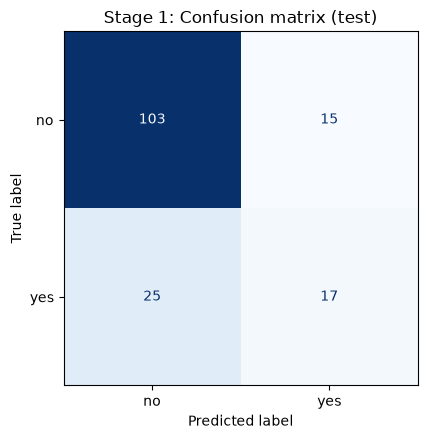

In [7]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

if TASK1 == 'classification':
    pred_c = s1_final.predict(X_test)
    print(f'Accuracy    = {accuracy_score(yc_test, pred_c):.4f}')
    print(f'F1 macro    = {f1_score(yc_test, pred_c, average="macro"):.4f}')
    print(f'F1 weighted = {f1_score(yc_test, pred_c, average="weighted"):.4f}')
    if K == 2:
        print(f'F1 (positive = "{class_names[1]}") = {f1_score(yc_test, pred_c):.4f}')
    print()
    print(classification_report(yc_test, pred_c, target_names=class_names, digits=3))
    fig, ax = plt.subplots(figsize=(4.5 + 0.4 * K, 4 + 0.3 * K))
    ConfusionMatrixDisplay(confusion_matrix(yc_test, pred_c), display_labels=class_names).plot(ax=ax, cmap='Blues', colorbar=False)
    plt.title('Stage 1: Confusion matrix (test)'); plt.show()
else:
    p = s1_final.predict(X_test)
    print(f'R2   = {r2_score(yr_test, p):.4f}')
    print(f'RMSE = {np.sqrt(mean_squared_error(yr_test, p)):.4f}')
    print(f'MAE  = {mean_absolute_error(yr_test, p):.4f}')
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].scatter(yr_test, p, alpha=0.5)
    lim = [min(yr_test.min(), p.min()), max(yr_test.max(), p.max())]
    ax[0].plot(lim, lim, 'r--'); ax[0].set_xlabel('Actual'); ax[0].set_ylabel('Predicted')
    ax[0].set_title('Stage 1: Actual vs Predicted')
    ax[1].scatter(p, yr_test - p, alpha=0.5); ax[1].axhline(0, color='r', linestyle='--')
    ax[1].set_xlabel('Predicted'); ax[1].set_ylabel('Residual'); ax[1].set_title('Residual')
    plt.tight_layout(); plt.show()

## 4. สร้าง feature ให้ Stage 2 (แบบ out-of-fold — ไม่ leak)

ถ้าเอาผลจากโมเดลที่ fit กับ train มาเป็น feature ของ train เอง Stage 2 จะได้เปรียบแบบไม่ยุติธรรม (leak)
จึงใช้ **out-of-fold prediction** สำหรับ train แทน ส่วน test ใช้โมเดลตัวสุดท้าย

In [8]:
from sklearn.model_selection import cross_val_predict

prep_final = s1_final.named_steps['prep']
Xtr_p = prep_final.transform(X_train)
Xte_p = prep_final.transform(X_test)
base_names = list(prep_final.get_feature_names_out())

def make_stage2(Xp, extra):
    return np.hstack([Xp] + extra) if extra else Xp

if TASK1 == 'classification':
    oof_proba = cross_val_predict(clone(s1_final), X_train, yc_train, cv=cv_cls, method='predict_proba')
    te_proba  = s1_final.predict_proba(X_test)
    oof_acc = accuracy_score(yc_train, oof_proba.argmax(1))
    fit_acc = accuracy_score(yc_train, s1_final.predict(X_train))
    te_acc  = accuracy_score(yc_test, te_proba.argmax(1))
    print(f'Stage1 acc  OOF(train) = {oof_acc:.4f}')
    print(f'Stage1 acc  fit(train) = {fit_acc:.4f}   <- สูงกว่า OOF มาก = โมเดลจำ train')
    print(f'Stage1 acc  test       = {te_acc:.4f}')
    s1_fit_m, s1_oof_m, s1_test_m = fit_acc, oof_acc, te_acc

    def extra_of(proba):
        e = []
        if ADD_PROBA:        e.append(proba)
        if ADD_CLASS_ONEHOT: e.append(np.eye(K)[proba.argmax(1)])
        return e
    Ztr, Zte = make_stage2(Xtr_p, extra_of(oof_proba)), make_stage2(Xte_p, extra_of(te_proba))
    Ztr_true, Zte_true = make_stage2(Xtr_p, [np.eye(K)[yc_train]]), make_stage2(Xte_p, [np.eye(K)[yc_test]])

    z_names = list(base_names)
    if ADD_PROBA:         z_names += [f'proba_{c}' for c in class_names]
    if ADD_CLASS_ONEHOT:  z_names += [f'predclass_{c}' for c in class_names]
    set_labels = ['ไม่มี class', 'class ทำนาย (OOF)', 'class จริง (รั่ว)']
else:
    oof_val = cross_val_predict(clone(s1_final), X_train, yr_train, cv=cv_reg)
    te_val  = s1_final.predict(X_test)
    oof_r2 = r2_score(yr_train, oof_val)
    fit_r2 = r2_score(yr_train, s1_final.predict(X_train))
    te_r2  = r2_score(yr_test, te_val)
    print(f'Stage1 R2  OOF(train) = {oof_r2:.4f}')
    print(f'Stage1 R2  fit(train) = {fit_r2:.4f}   <- สูงกว่า OOF มาก = โมเดลจำ train')
    print(f'Stage1 R2  test       = {te_r2:.4f}')
    s1_fit_m, s1_oof_m, s1_test_m = fit_r2, oof_r2, te_r2

    NBINS = 5
    bins = np.quantile(oof_val, np.linspace(0, 1, NBINS + 1))   # ขอบ bin จาก train(OOF) เท่านั้น
    # scale ค่าที่ทำนายด้วยสถิติของ train(OOF) — มิฉะนั้นสเกล ~20,000 จะเข้าปะทะโมเดลระยะทาง (KNN/SVC)
    vm, vs = float(np.mean(oof_val)), float(np.std(oof_val)) + 1e-12
    def to_bins(v):
        return np.eye(NBINS)[np.clip(np.digitize(v, bins[1:-1], right=True), 0, NBINS - 1)]
    def extra_of(v):
        e = []
        if ADD_PRED_VALUE: e.append((np.asarray(v, float).reshape(-1, 1) - vm) / vs)
        if ADD_PRED_BIN:   e.append(to_bins(v))
        return e
    Ztr, Zte = make_stage2(Xtr_p, extra_of(oof_val)), make_stage2(Xte_p, extra_of(te_val))
    Ztr_true, Zte_true = make_stage2(Xtr_p, [(yr_train.reshape(-1, 1) - vm) / vs]), make_stage2(Xte_p, [(yr_test.reshape(-1, 1) - vm) / vs])

    z_names = list(base_names)
    if ADD_PRED_VALUE: z_names += ['pred_value']
    if ADD_PRED_BIN:   z_names += [f'predbin_{i}' for i in range(NBINS)]
    set_labels = ['ไม่มีค่าทำนาย', 'ค่าทำนาย (OOF)', 'ค่าจริง (รั่ว)']

print('Stage-2 feature shape:', Ztr.shape, Zte.shape)

Stage1 acc  OOF(train) = 0.7969
Stage1 acc  fit(train) = 0.8031   <- สูงกว่า OOF มาก = โมเดลจำ train
Stage1 acc  test       = 0.7500
Stage-2 feature shape: (640, 13) (160, 13)


## 5. Stage 2

### 5.1 เปรียบเทียบโมเดล (CV บน train)

In [9]:
def rank_stage2(Ztr_, Zte_):
    rows = []
    if TASK2 == 'regression':
        cand = {'Baseline(mean)': lambda: DummyRegressor(), **REG_MODELS}
        y_tr, y_te = yr_train, yr_test
    else:
        cand = {'Baseline(majority)': lambda: DummyClassifier(strategy='most_frequent'), **CLS_MODELS}
        y_tr, y_te = yc_train, yc_test
    for name, mk in cand.items():
        m = mk()
        if TASK2 == 'regression':
            cvs = cross_val_score(m, Ztr_, y_tr, cv=cv_reg, scoring='r2', n_jobs=-1)
            m.fit(Ztr_, y_tr); p = m.predict(Zte_)
            rows.append({'model': name, 'R2_train': r2_score(y_tr, m.predict(Ztr_)),
                         'CV_R2': cvs.mean(), 'CV_R2_std': cvs.std(),
                         'R2_test': r2_score(y_te, p),
                         'RMSE_test': np.sqrt(mean_squared_error(y_te, p)),
                         'MAE_test': mean_absolute_error(y_te, p)})
            key = 'CV_R2'
        else:
            cvs = cross_val_score(m, Ztr_, y_tr, cv=cv_cls, scoring=CLS_METRIC, n_jobs=-1)
            m.fit(Ztr_, y_tr); p = m.predict(Zte_)
            row = {'model': name, 'CV_' + CLS_METRIC: cvs.mean(), 'CV_std': cvs.std(),
                   'Test_acc': accuracy_score(y_te, p)}
            if CLS_METRIC == 'f1_macro':
                row['Test_f1_macro'] = f1_score(y_te, p, average='macro')
            elif CLS_METRIC == 'f1_weighted':
                row['Test_f1_weighted'] = f1_score(y_te, p, average='weighted')
            rows.append(row)
            key = 'CV_' + CLS_METRIC
    out = pd.DataFrame(rows).sort_values(key, ascending=False).reset_index(drop=True)
    out.insert(0, 'rank', out.index + 1)
    return out

s2_df = rank_stage2(Ztr, Zte)
display(s2_df.round(4))
if TASK2 == 'regression':
    print('ดู: R2_train สูงกว่า CV/test มาก = overfit | ต้องชนะ Baseline(mean) ที่ R2 ~ 0')
else:
    print('ดู: ต้องชนะ Baseline(majority)')

,rank,model,R2_train,CV_R2,CV_R2_std,R2_test,RMSE_test,MAE_test
0,1,Ridge,0.6740,0.6572,0.0396,0.5445,2981.6489,2360.9294
1,2,Lasso,0.6741,0.6570,0.0395,0.5440,2983.4374,2362.0126
2,3,Linear,0.6741,0.6570,0.0394,0.5439,2983.6614,2362.0903
3,4,ElasticNet,0.6706,0.6561,0.0378,0.5509,2960.6236,2336.2367
4,5,MLP,0.6622,0.6443,0.0431,0.5462,2976.1418,2337.7674
5,6,XGBoost,0.8556,0.6201,0.0461,0.4779,3192.4522,2519.6837
6,7,Stacking,0.8295,0.6177,0.0536,0.4924,3147.6369,2483.1912
7,8,GradBoost,0.8288,0.6138,0.0650,0.4822,3179.1416,2501.9979
8,9,RandomForest,0.9436,0.5816,0.0616,0.4548,3262.2217,2615.3926
9,10,LightGBM,0.9564,0.5508,0.0712,0.3900,3450.5812,2732.8483


ดู: R2_train สูงกว่า CV/test มาก = overfit | ต้องชนะ Baseline(mean) ที่ R2 ~ 0


### 5.2 Ablation: Stage 1 ช่วย Stage 2 จริงไหม

ทดสอบ 3 แบบ: **ไม่มี** feature จาก Stage 1 / แบบ **ทำนาย (OOF)** = flow จริง / แบบ **ของจริง** = รั่ว (ใช้เทียบขีดบนเท่านั้น ห้ามใช้จริง)

อ่านผล: "ทำนาย" ≈ "ไม่มี" << "จริง" → Stage 1 ยังไม่คมพอ (ควรไป improve Stage 1 ก่อน)

In [10]:
best_s2_name = s2_df[~s2_df.model.str.startswith('Baseline')].iloc[0]['model']
print('โมเดล Stage 2 ที่ใช้เทียบ:', best_s2_name, '\n')

sets = {set_labels[0]: (Xtr_p, Xte_p),
        set_labels[1]: (Ztr, Zte),
        set_labels[2]: (Ztr_true, Zte_true)}
rows = []
for label, (A, B) in sets.items():
    m = (REG_MODELS if TASK2 == 'regression' else CLS_MODELS)[best_s2_name]()
    if TASK2 == 'regression':
        cvs = cross_val_score(m, A, yr_train, cv=cv_reg, scoring='r2', n_jobs=-1)
        m.fit(A, yr_train); p = m.predict(B)
        rows.append({'feature set': label, 'CV_R2': cvs.mean(), 'R2_test': r2_score(yr_test, p),
                     'RMSE_test': np.sqrt(mean_squared_error(yr_test, p)),
                     'MAE_test': mean_absolute_error(yr_test, p)})
    else:
        cvs = cross_val_score(m, A, yc_train, cv=cv_cls, scoring=CLS_METRIC, n_jobs=-1)
        m.fit(A, yc_train); p = m.predict(B)
        row = {'feature set': label, 'CV_' + CLS_METRIC: cvs.mean(), 'Test_acc': accuracy_score(yc_test, p)}
        if CLS_METRIC == 'f1_macro':
            row['Test_f1_macro'] = f1_score(yc_test, p, average='macro')
        elif CLS_METRIC == 'f1_weighted':
            row['Test_f1_weighted'] = f1_score(yc_test, p, average='weighted')
        rows.append(row)
display(pd.DataFrame(rows).round(4))

โมเดล Stage 2 ที่ใช้เทียบ: Ridge 



,feature set,CV_R2,R2_test,RMSE_test,MAE_test
0,ไม่มี class,0.6578,0.5479,2970.5874,2355.6013
1,class ทำนาย (OOF),0.6572,0.5445,2981.6489,2360.9294
2,class จริง (รั่ว),0.6583,0.5428,2987.4818,2382.2493


### 5.3 เจาะ hyperparameter Stage 2 + fit ตัวสุดท้าย (`s2_final`)

In [11]:
TUNE_S2 = True
S2_PICK = None        # None = อันดับ 1 จาก CV | หรือระบุชื่อ เช่น 'XGBoost'

y2_tr = yr_train if TASK2 == 'regression' else yc_train
s2_pick = S2_PICK or best_s2_name
factory = (REG_MODELS if TASK2 == 'regression' else CLS_MODELS)[s2_pick]
base_model = factory()
grid = grid_with_prefix(TASK2, s2_pick, '')
if TUNE_S2 and grid:
    gs = GridSearchCV(base_model, grid, cv=(cv_reg if TASK2 == 'regression' else cv_cls),
                      scoring=('r2' if TASK2 == 'regression' else CLS_METRIC), n_jobs=-1)
    gs.fit(Ztr, y2_tr)
    s2_final = gs.best_estimator_
    print('เลือก:', s2_pick, '| best params:', gs.best_params_, f'| CV = {gs.best_score_:.4f}')
    for k_, vals in grid.items():
        nums = [v for v in vals if isinstance(v, (int, float)) and not isinstance(v, bool)]
        if len(nums) > 1 and gs.best_params_[k_] in (min(nums), max(nums)):
            print(f'!! {k_}={gs.best_params_[k_]} ชนขอบ grid -> ควรขยาย grid')
else:
    s2_final = base_model.fit(Ztr, y2_tr)
    print('เลือก:', s2_pick, '(ไม่ tune)')

p2 = s2_final.predict(Zte)
if TASK2 == 'regression':
    print(f'\nStage 2 บน test:  R2={r2_score(yr_test, p2):.4f}  RMSE={np.sqrt(mean_squared_error(yr_test, p2)):.4f}  MAE={mean_absolute_error(yr_test, p2):.4f}')
    print(f'R2 train = {r2_score(yr_train, s2_final.predict(Ztr)):.4f}   (เทียบกับ test ดู overfit)')
else:
    print(f'\nStage 2 บน test:  Accuracy={accuracy_score(yc_test, p2):.4f}  F1 macro={f1_score(yc_test, p2, average="macro"):.4f}  F1 weighted={f1_score(yc_test, p2, average="weighted"):.4f}')
    print(f'F1 macro train = {f1_score(yc_train, s2_final.predict(Ztr), average="macro"):.4f}   (เทียบกับ test ดู overfit)')

เลือก: Ridge | best params: {'alpha': 10} | CV = 0.6576

Stage 2 บน test:  R2=0.5477  RMSE=2971.2076  MAE=2352.3353
R2 train = 0.6735   (เทียบกับ test ดู overfit)


## 6. ทำนายแบบ end-to-end (เหมือนเอาไปใช้กับข้อมูลใหม่)

`predict_all(df_new)` รับ dataframe ใหม่ (ต้องมีคอลัมน์ feature ครบ) → วิ่ง Stage 1 → สร้าง feature → Stage 2 → คืนทั้ง class และค่า

In [12]:
def predict_all(df_new):
    Xn = clean_X(df_new)
    if TASK1 == 'classification':
        proba = s1_final.predict_proba(Xn)
        Zn = make_stage2(s1_final.named_steps['prep'].transform(Xn), extra_of(proba))
        out = pd.DataFrame({'pred_class': le.inverse_transform(proba.argmax(1))}, index=df_new.index)
        for i, c in enumerate(class_names):
            out['proba_' + c] = proba[:, i]
        out['pred_value'] = s2_final.predict(Zn)
    else:
        val = s1_final.predict(Xn)
        Zn = make_stage2(s1_final.named_steps['prep'].transform(Xn), extra_of(val))
        out = pd.DataFrame({'pred_value': val}, index=df_new.index)
        out['pred_class'] = le.inverse_transform(s2_final.predict(Zn))
        if hasattr(s2_final, 'predict_proba'):
            proba = s2_final.predict_proba(Zn)
            for i, c in enumerate(class_names):
                out['proba_' + c] = proba[:, i]
    return out

test_raw = data.iloc[idx_te]
res = predict_all(test_raw)

print('=== ทำนาย end-to-end บน test ===')
if DIRECTION == 'cls2reg':
    print(f'[Stage 1] Accuracy={accuracy_score(test_raw[CLASS_COL], res.pred_class):.4f}  '
          f'F1 macro={f1_score(test_raw[CLASS_COL], res.pred_class, average="macro"):.4f}')
    print(f'[Stage 2] R2={r2_score(yr_test, res.pred_value):.4f}  '
          f'RMSE={np.sqrt(mean_squared_error(yr_test, res.pred_value)):.4f}  '
          f'MAE={mean_absolute_error(yr_test, res.pred_value):.4f}')
else:
    print(f'[Stage 1] R2={r2_score(yr_test, res.pred_value):.4f}  '
          f'RMSE={np.sqrt(mean_squared_error(yr_test, res.pred_value)):.4f}  '
          f'MAE={mean_absolute_error(yr_test, res.pred_value):.4f}')
    print(f'[Stage 2] Accuracy={accuracy_score(test_raw[CLASS_COL], res.pred_class):.4f}  '
          f'F1 macro={f1_score(test_raw[CLASS_COL], res.pred_class, average="macro"):.4f}')
display(res.head(10).round(3))

# ถ้าต้องการ export:
# res[['pred_class', 'pred_value']].to_csv('predictions.csv', index=False)

=== ทำนาย end-to-end บน test ===
[Stage 1] Accuracy=0.7500  F1 macro=0.6484
[Stage 2] R2=0.5477  RMSE=2971.2076  MAE=2352.3353


,pred_class,proba_no,proba_yes,pred_value
296,no,0.692,0.308,18432.286
295,no,0.517,0.483,18133.348
380,no,0.840,0.160,23540.412
586,no,0.858,0.142,19126.287
678,no,0.894,0.106,20430.365
581,no,0.983,0.017,21602.706
651,no,0.997,0.003,25916.756
145,no,0.834,0.166,21114.688
778,no,0.961,0.039,19035.981
402,no,0.971,0.029,17810.183


C:\Users\computer\AppData\Local\Temp\ipykernel_15968\1387760853.py:28: UserWarning: Glyph 3626 (\N{THAI CHARACTER SO SUA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\computer\AppData\Local\Temp\ipykernel_15968\1387760853.py:28: UserWarning: Glyph 3592 (\N{THAI CHARACTER CHO CHAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\computer\AppData\Local\Temp\ipykernel_15968\1387760853.py:28: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\computer\AppData\Local\Temp\ipykernel_15968\1387760853.py:28: UserWarning: Glyph 3591 (\N{THAI CHARACTER NGO NGU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\computer\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3626 (\N{THAI CHARACTER SO SUA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\com

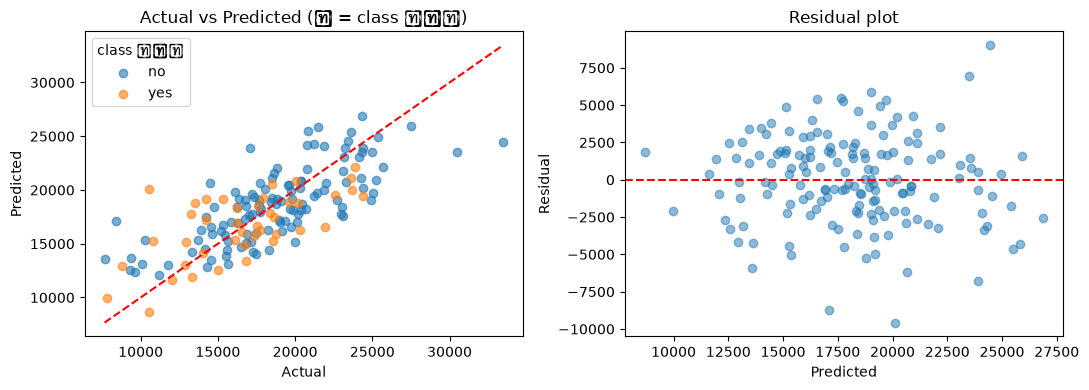

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, roc_curve, auc

if TASK2 == 'regression':
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for k, name in enumerate(class_names):
        mk = yc_test == k
        ax[0].scatter(yr_test[mk], res.pred_value.to_numpy()[mk], alpha=0.6, label=name)
    lo = min(yr_test.min(), res.pred_value.min()); hi = max(yr_test.max(), res.pred_value.max())
    ax[0].plot([lo, hi], [lo, hi], 'r--'); ax[0].legend(title='class จริง')
    ax[0].set_xlabel('Actual'); ax[0].set_ylabel('Predicted')
    ax[0].set_title('Actual vs Predicted (สี = class จริง)')
    ax[1].scatter(res.pred_value, yr_test - res.pred_value, alpha=0.5); ax[1].axhline(0, color='r', linestyle='--')
    ax[1].set_xlabel('Predicted'); ax[1].set_ylabel('Residual'); ax[1].set_title('Residual plot')
else:
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    pred_enc = le.transform(res.pred_class)
    proba_col = 'proba_' + class_names[1] if (K == 2 and 'proba_' + class_names[1] in res.columns) else None
    if proba_col:
        fpr, tpr, _ = roc_curve((yc_test == 1).astype(int), res[proba_col])
        ax[0].plot(fpr, tpr, label=f'AUC = {auc(fpr, tpr):.3f}')
        ax[0].plot([0, 1], [0, 1], 'k--'); ax[0].legend()
        ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].set_title('ROC (Stage 2)')
    else:
        ax[0].axis('off')
    ConfusionMatrixDisplay(confusion_matrix(yc_test, pred_enc), display_labels=class_names).plot(ax=ax[1], cmap='Blues', colorbar=False)
    ax[1].set_title('Stage 2: Confusion (test)')
plt.tight_layout(); plt.show()

## 7. ทางเลือกอื่น

### 7.1 แยกโมเดลตามกลุ่ม (แทนการเอาผล Stage 1 มาเป็น feature)

- `cls2reg`: ฝึก regressor แยกของแต่ละ class ที่ทำนาย (ถ้า class กำหนด y ค่อนข้างชัด วิธีนี้มักชนะ)
- `reg2cls`: ฝึก classifier แยกของแต่ละ bin ของค่าที่ทำนาย (mirror ของอีกฝั่ง)

In [14]:
MIN_PER_GROUP = 30

if DIRECTION == 'cls2reg':
    glob = clone(s2_final).fit(Xtr_p, yr_train)
    per = {}
    for k in range(K):
        mk = yc_train == k
        if mk.sum() >= MIN_PER_GROUP:
            per[k] = clone(s2_final).fit(Xtr_p[mk], yr_train[mk])
    print('class ที่มีข้อมูลพอ:', [class_names[k] for k in per])
    te_route = te_proba.argmax(1)
    p_exp = glob.predict(Xte_p)
    for k, m_ in per.items():
        mk = te_route == k
        if mk.any():
            p_exp[mk] = m_.predict(Xte_p[mk])
    print(f'Per-class regression : R2={r2_score(yr_test, p_exp):.4f}  RMSE={np.sqrt(mean_squared_error(yr_test, p_exp)):.4f}')
    print(f'Class-as-feature     : R2={r2_score(yr_test, p2):.4f}  RMSE={np.sqrt(mean_squared_error(yr_test, p2)):.4f}')
else:
    glob = clone(s2_final).fit(Xtr_p, yc_train)
    bin_tr = np.clip(np.digitize(oof_val, bins[1:-1], right=True), 0, NBINS - 1)
    per = {}
    for b in range(NBINS):
        mk = bin_tr == b
        if mk.sum() >= MIN_PER_GROUP:
            per[b] = clone(s2_final).fit(Xtr_p[mk], yc_train[mk])
    print('bin ที่มีข้อมูลพอ:', sorted(per))
    bin_te = np.clip(np.digitize(te_val, bins[1:-1], right=True), 0, NBINS - 1)
    p_exp = glob.predict(Xte_p)
    for b, m_ in per.items():
        mk = bin_te == b
        if mk.any():
            p_exp[mk] = m_.predict(Xte_p[mk])
    print(f'Per-bin classification : acc={accuracy_score(yc_test, p_exp):.4f}  F1 macro={f1_score(yc_test, p_exp, average="macro"):.4f}')
    print(f'Value-as-feature        : acc={accuracy_score(yc_test, p2):.4f}  F1 macro={f1_score(yc_test, p2, average="macro"):.4f}')

class ที่มีข้อมูลพอ: ['no', 'yes']
Per-class regression : R2=0.5337  RMSE=3016.8141
Class-as-feature     : R2=0.5477  RMSE=2971.2076


### 7.2 Permutation importance (วัดว่า feature ไหนสำคัญ — รวม feature ที่มาจาก Stage 1)

In [15]:
from sklearn.inspection import permutation_importance

if TASK2 == 'regression':
    r_ = permutation_importance(s2_final, Zte, yr_test, n_repeats=10, random_state=SEED, scoring='r2')
    print('Stage 2 (regression) top 12:')
else:
    r_ = permutation_importance(s2_final, Zte, yc_test, n_repeats=10, random_state=SEED, scoring=CLS_METRIC)
    print(f'Stage 2 (classification, drop ใน {CLS_METRIC}) top 12:')
imp2 = pd.Series(r_.importances_mean, index=z_names).sort_values(ascending=False)
print(imp2.head(12).round(4))

if TASK1 == 'classification':
    r1_ = permutation_importance(s1_final, X_test, yc_test, n_repeats=10, random_state=SEED, scoring=CLS_METRIC)
    print(f'\nStage 1 (classification, drop ใน {CLS_METRIC}) top 12:')
else:
    r1_ = permutation_importance(s1_final, X_test, yr_test, n_repeats=10, random_state=SEED, scoring='r2')
    print('\nStage 1 (regression, drop ใน R2) top 12:')
imp1 = pd.Series(r1_.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(imp1.head(12).round(4))

Stage 2 (regression) top 12:
num__income            1.0687
cat__region_N          0.0489
num__term_months       0.0429
num__prior_defaults    0.0260
cat__region_S          0.0128
cat__region_E          0.0011
cat__region_W          0.0010
num__emp_years         0.0010
num__age               0.0009
predclass_no           0.0001
predclass_yes          0.0001
proba_yes             -0.0007
dtype: float64



Stage 1 (classification, drop ใน f1_macro) top 12:
prior_defaults    0.0509
income            0.0388
region            0.0269
age               0.0218
term_months       0.0103
emp_years        -0.0022
dtype: float64


## 8. Self-check: data leak + overfit (ตรวจอัตโนมัติ)

ตรวจข้อเท็จจริงของ pipeline นี้ด้วยเงื่อนไขที่วัดได้ ถ้าข้อไหน `WARN` ให้กลับไปดูตามรายละเอียด

In [16]:
print('=' * 64)
print(' SELF-CHECK: DATA LEAK + OVERFIT ')
print('=' * 64)

checks = []

# ---------- leak ----------
n_dup = int(data.duplicated().sum())
checks.append(('ไม่มีแถวซ้ำหลังเตรียมข้อมูล', n_dup == 0, f'duplicates = {n_dup}'))

overlap = len(set(idx_tr.tolist()) & set(idx_te.tolist()))
checks.append(('train / test ไม่มีแถวซ้ำกัน', overlap == 0, f'overlap = {overlap}'))

p_tr = np.bincount(yc_train, minlength=K) / len(yc_train)
p_te = np.bincount(yc_test, minlength=K) / len(yc_test)
gap_cls = float(np.max(np.abs(p_tr - p_te)))
checks.append(('สัดส่วน class ใน train ≈ test (stratify ได้ผล)', gap_cls < 0.08, f'max diff = {gap_cls:.3f}'))

ok_finite = bool(np.isfinite(Ztr).all() and np.isfinite(Zte).all())
checks.append(('feature ของ Stage 2 ไม่มี NaN / inf', ok_finite, 'finite' if ok_finite else 'มีค่าไม่ finite!'))

checks.append(('Stage 2 ใช้ out-of-fold สำหรับ train', True, 'โดยการออกแบบ (cross_val_predict)'))

# ---------- overfit ----------
gap1 = s1_fit_m - s1_oof_m
checks.append(('Stage 1: fit(train) − OOF ไม่ห่างกันมาก', gap1 < 0.15,
               f'fit={s1_fit_m:.3f}, OOF={s1_oof_m:.3f}, gap={gap1:.3f}'))
checks.append(('Stage 1: OOF ≈ คะแนน test (generalize ได้)', abs(s1_oof_m - s1_test_m) < 0.10,
               f'OOF={s1_oof_m:.3f}, test={s1_test_m:.3f}'))

if TASK2 == 'regression':
    m_tr = r2_score(yr_train, s2_final.predict(Ztr))
    m_te = r2_score(yr_test, s2_final.predict(Zte))
    unit = 'R2'
else:
    m_tr = f1_score(yc_train, s2_final.predict(Ztr), average='macro')
    m_te = f1_score(yc_test, s2_final.predict(Zte), average='macro')
    unit = 'F1 macro'
checks.append((f'Stage 2: {unit} train − test ไม่ห่างกันมาก', (m_tr - m_te) < 0.15,
               f'train={m_tr:.3f}, test={m_te:.3f}, gap={m_tr - m_te:.3f}'))

print()
for label, ok, detail in checks:
    print(f"[{'PASS' if ok else 'WARN'}] {label}")
    print(f'       -> {detail}')

n_warn = sum(1 for _, ok, _ in checks if not ok)
print()
if n_warn == 0:
    print(' ผ่านทุกข้อ — ไม่พบสัญญาณ data leak / overfit จากการตรวจอัตโนมัติ ')
else:
    print(f' !! มี {n_warn} ข้อควรกลับไปดู (อ่านรายละเอียดข้างบน) ')

print()
print('หมายเหตุ: การตัดสินใจระดับคอลัมน์ (null / cardinality / แปลงข้อความเป็นตัวเลข)')
print('ใช้สถิติจากข้อมูลทั้งหมด (รวม test) — เป็นแนวปฏิบัติทั่วไปและกระทบต่ำมาก')
print('แต่ถ้าอยากเข้มงวดสุด ๆ ให้ย้ายขั้นตอนพวกนี้ไปทำหลัง split บน train เท่านั้น')

 SELF-CHECK: DATA LEAK + OVERFIT 

[PASS] ไม่มีแถวซ้ำหลังเตรียมข้อมูล
       -> duplicates = 0
[PASS] train / test ไม่มีแถวซ้ำกัน
       -> overlap = 0
[PASS] สัดส่วน class ใน train ≈ test (stratify ได้ผล)
       -> max diff = 0.002
[PASS] feature ของ Stage 2 ไม่มี NaN / inf
       -> finite
[PASS] Stage 2 ใช้ out-of-fold สำหรับ train
       -> โดยการออกแบบ (cross_val_predict)
[PASS] Stage 1: fit(train) − OOF ไม่ห่างกันมาก
       -> fit=0.803, OOF=0.797, gap=0.006
[PASS] Stage 1: OOF ≈ คะแนน test (generalize ได้)
       -> OOF=0.797, test=0.750
[PASS] Stage 2: R2 train − test ไม่ห่างกันมาก
       -> train=0.674, test=0.548, gap=0.126

 ผ่านทุกข้อ — ไม่พบสัญญาณ data leak / overfit จากการตรวจอัตโนมัติ 

หมายเหตุ: การตัดสินใจระดับคอลัมน์ (null / cardinality / แปลงข้อความเป็นตัวเลข)
ใช้สถิติจากข้อมูลทั้งหมด (รวม test) — เป็นแนวปฏิบัติทั่วไปและกระทบต่ำมาก
แต่ถ้าอยากเข้มงวดสุด ๆ ให้ย้ายขั้นตอนพวกนี้ไปทำหลัง split บน train เท่านั้น


---
## สรุปวิธีใช้

1. เซลล์ 0 → 1 → 2 (แก้ `CONFIG` ให้ตรงข้อมูล) → 3 → 4 → 5 → 6 → 7 → 8 ตามลำดับ
2. **สลับทิศทางได้**: ตั้ง `DIRECTION = 'cls2reg'` หรือ `'reg2cls'` แล้วรันใหม่ตั้งแต่เซลล์ 1
3. flow กัน leak โดยหลัก: stratified split → CV เลือกโมเดลบน train → tune → **OOF prediction** สร้าง feature ให้ Stage 2 → วัดบน test
4. ข้อมูลสกปรกที่รองรับอัตโนมัติ: duplicates / NaN / inf / markers ('na','-','null') / ตัวเลขเป็นข้อความ / ID / datetime / ค่าคงที่ / outlier (winsorize) / unknown category
5. ถ้า ablation (5.2) ออกมา "ทำนาย ≈ ไม่มี" แปลว่า Stage 1 ยังไม่คม → กลับไป tune Stage 1 ก่อน
6. self-check (section 8) ต้องได้ PASS ทุกข้อก่อนเอาผลไปใช้
7. ถ้าจะเอาไปใช้จริงกับข้อมูลใหม่: `predict_all(new_df)`
8. อยากใช้ LightGBM ด้วย: `pip install lightgbm` แล้วรันใหม่ (notebook จะหยิบมาใช้อัตโนมัติ)